In [155]:
import re
from pathlib import Path
import pandas as pd
import json
import subprocess
import numpy as np
import seaborn as sns

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from copy import deepcopy
import textwrap
from PIL import Image
import matplotlib.image as mpimg


In [156]:
cmap_red = LinearSegmentedColormap.from_list(
    "cmap_red",
    [
        (0.0, "#ffffff"),  # 0%: white
        (0.5, "#ffb7b7"),  # 50%: light red
        (0.99, "#ff5959"),  # 99%: dark red
        (1.0, "#ff0000"),  # 100%: red
    ],
)

cmap_blue = LinearSegmentedColormap.from_list(
    "cmap_blue",
    [
        (0.0, "#ffffff"),  # 0%: white
        (0.5, "#b7dcff"),  # 50%: light blue
        (0.99, "#59a7ff"),  # 99%: dark blue
        (1.0, "#007fff"),  # 100%: blue
    ],
)

project_dir = Path(r"C:\Users\evan\Desktop\Personal Projects\Pokemon Stat Optimize")
sprite_dir = project_dir / "images" / "sprites"


In [157]:
stat_names = {"hp": "hp", "atk": "atk", "def": "def", "spa": "spa", "spd": "spd", "spe": "spe"}

def parse_showdown_set(block):
    lines = [line.strip() for line in block.splitlines() if line.strip()]
    pokemon_text, separator, item = lines[0].partition(" @ ")
    pokemon_text = re.sub(r"\s+\([MF]\)$", "", pokemon_text.strip())
    species_match = re.search(r"\(([^()]+)\)$", pokemon_text)
    pokemon = {"name": species_match.group(1).strip() if species_match else pokemon_text,
               "level": 50, "evs": {}, "moves": []}
    if separator:
        pokemon["item"] = item.strip()

    for line in lines[1:]:
        if line.startswith("- "):
            pokemon["moves"].append(line[2:].strip())
        elif line.lower().startswith("ability:"):
            pokemon["ability"] = line.split(":", 1)[1].strip()
        elif line.lower().startswith("level:"):
            pokemon["level"] = int(line.split(":", 1)[1].strip())
        elif line.lower().startswith("evs:"):
            for entry in line.split(":", 1)[1].split("/"):
                amount, stat = entry.strip().split(maxsplit=1)
                pokemon["evs"][stat_names[stat.lower()]] = int(amount)
        elif line.lower().endswith(" nature"):
            pokemon["nature"] = line[:-len(" nature")].strip()
    return pokemon

def read_showdown_team(path):
    text = path.read_text(encoding="utf-8").strip()
    return [parse_showdown_set(block) for block in re.split(r"\r?\n\s*\r?\n", text) if block.strip()]

attackers = read_showdown_team(project_dir / "attackers.txt")
defenders = read_showdown_team(project_dir / "defenders.txt")

print(attackers)
print(defenders)


[{'name': 'Salamence-Mega', 'level': 50, 'evs': {'hp': 17, 'atk': 29, 'spd': 20}, 'moves': ['Double-Edge', 'Draco Meteor', 'Tailwind', 'Protect'], 'item': 'Salamencite', 'ability': 'Aerilate', 'nature': 'Lonely'}, {'name': 'Indeedee-F', 'level': 50, 'evs': {'hp': 32, 'def': 32, 'spd': 2}, 'moves': ['Psychic', 'Helping Hand', 'Trick Room', 'Follow Me'], 'item': 'Psychic Seed', 'ability': 'Psychic Surge', 'nature': 'Relaxed'}, {'name': 'Mr. Rime', 'level': 50, 'evs': {'hp': 5, 'spa': 31, 'spd': 8, 'spe': 22}, 'moves': ['Fake Out', 'Ice Beam', 'Expanding Force', 'Protect'], 'item': 'Life Orb', 'ability': 'Screen Cleaner', 'nature': 'Modest'}, {'name': 'Furfrou', 'level': 50, 'evs': {'hp': 32, 'atk': 30, 'def': 4}, 'moves': ['Cotton Guard', 'Last Resort'], 'item': 'Leftovers', 'ability': 'Fur Coat', 'nature': 'Adamant'}, {'name': 'Pelipper', 'level': 50, 'evs': {'hp': 32, 'spa': 10, 'spd': 13, 'spe': 11}, 'moves': ['Weather Ball', 'Hurricane', 'Wide Guard', 'Tailwind'], 'item': 'Sitrus Ber

In [158]:
matchup_requests = [
    {"attacker": {key: value for key, value in attacker.items() if key != "moves"},
     "defender": {key: value for key, value in defender.items() if key != "moves"},
     "move": move,
     "field": {"gameType": "Doubles"}}
    for attacker in attackers
    for defender in defenders
    for move in attacker["moves"]
]

for request in matchup_requests:
    participants = {
        request["attacker"]["name"],
        request["defender"]["name"],
    }

    field = request["field"]

    if "Indeedee-F" in participants:
        field["terrain"] = "Psychic"

    if "Mr. Rime" in participants:
        field["terrain"] = "Psychic"

    if "Froslass-Mega" in participants:
        field["weather"] = "Snow"
    elif "Pelipper" in participants:
        field["weather"] = "Rain"

    if field:
        request["field"] = field

matchup_requests

[{'attacker': {'name': 'Salamence-Mega',
   'level': 50,
   'evs': {'hp': 17, 'atk': 29, 'spd': 20},
   'item': 'Salamencite',
   'ability': 'Aerilate',
   'nature': 'Lonely'},
  'defender': {'name': 'Froslass-Mega',
   'level': 50,
   'evs': {'hp': 30, 'spa': 13, 'spe': 23},
   'item': 'Froslassite',
   'ability': 'Snow Warning',
   'nature': 'Timid'},
  'move': 'Double-Edge',
  'field': {'gameType': 'Doubles', 'weather': 'Snow'}},
 {'attacker': {'name': 'Salamence-Mega',
   'level': 50,
   'evs': {'hp': 17, 'atk': 29, 'spd': 20},
   'item': 'Salamencite',
   'ability': 'Aerilate',
   'nature': 'Lonely'},
  'defender': {'name': 'Froslass-Mega',
   'level': 50,
   'evs': {'hp': 30, 'spa': 13, 'spe': 23},
   'item': 'Froslassite',
   'ability': 'Snow Warning',
   'nature': 'Timid'},
  'move': 'Draco Meteor',
  'field': {'gameType': 'Doubles', 'weather': 'Snow'}},
 {'attacker': {'name': 'Salamence-Mega',
   'level': 50,
   'evs': {'hp': 17, 'atk': 29, 'spd': 20},
   'item': 'Salamencite'

In [159]:
try:
    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": matchup_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

move_results = json.loads(result.stdout)
move_results

[{'attacker': 'Salamence-Mega',
  'defender': 'Froslass-Mega',
  'move': 'Double-Edge',
  'category': 'Physical',
  'damage': [127,
   129,
   130,
   132,
   133,
   135,
   136,
   138,
   139,
   141,
   142,
   144,
   145,
   147,
   148,
   151],
  'maxDamage': 151,
  'minDamage': 127,
  'description': '29+ Atk Aerilate Salamence-Mega Double-Edge vs. 30 HP / 0 Def Froslass-Mega in Snow: 127-151 (72.5 - 86.2%) -- guaranteed 2HKO',
  'attackerStats': {'hp': 187,
   'atk': 213,
   'def': 135,
   'spa': 140,
   'spd': 130,
   'spe': 140},
  'defenderStats': {'hp': 175,
   'atk': 90,
   'def': 90,
   'spa': 173,
   'spd': 120,
   'spe': 179}},
 {'attacker': 'Salamence-Mega',
  'defender': 'Froslass-Mega',
  'move': 'Draco Meteor',
  'category': 'Special',
  'damage': [85, 87, 88, 88, 90, 91, 91, 93, 94, 94, 96, 97, 97, 99, 100, 102],
  'maxDamage': 102,
  'minDamage': 85,
  'description': '0 SpA Salamence-Mega Draco Meteor vs. 30 HP / 0 SpD Froslass-Mega: 85-102 (48.5 - 58.2%) -- 96.9

In [160]:
matchup_df = pd.DataFrame(move_results)
matchup_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attackerStats,defenderStats
0,Salamence-Mega,Froslass-Mega,Double-Edge,Physical,"[127, 129, 130, 132, 133, 135, 136, 138, 139, ...",151,127,29+ Atk Aerilate Salamence-Mega Double-Edge vs...,"{'hp': 187, 'atk': 213, 'def': 135, 'spa': 140...","{'hp': 175, 'atk': 90, 'def': 90, 'spa': 173, ..."
1,Salamence-Mega,Froslass-Mega,Draco Meteor,Special,"[85, 87, 88, 88, 90, 91, 91, 93, 94, 94, 96, 9...",102,85,0 SpA Salamence-Mega Draco Meteor vs. 30 HP / ...,"{'hp': 187, 'atk': 213, 'def': 135, 'spa': 140...","{'hp': 175, 'atk': 90, 'def': 90, 'spa': 173, ..."
2,Salamence-Mega,Froslass-Mega,Tailwind,Status,0,0,0,Salamence-Mega Tailwind vs. Froslass-Mega: 0-0...,"{'hp': 187, 'atk': 213, 'def': 135, 'spa': 140...","{'hp': 175, 'atk': 90, 'def': 90, 'spa': 173, ..."
3,Salamence-Mega,Froslass-Mega,Protect,Status,0,0,0,Salamence-Mega Protect vs. Froslass-Mega: 0-0 ...,"{'hp': 187, 'atk': 213, 'def': 135, 'spa': 140...","{'hp': 175, 'atk': 90, 'def': 90, 'spa': 173, ..."
4,Salamence-Mega,Garchomp-Mega-Z,Double-Edge,Physical,"[165, 166, 169, 171, 172, 175, 177, 178, 180, ...",195,165,29+ Atk Aerilate Salamence-Mega Double-Edge vs...,"{'hp': 187, 'atk': 213, 'def': 135, 'spa': 140...","{'hp': 185, 'atk': 135, 'def': 105, 'spa': 212..."
...,...,...,...,...,...,...,...,...,...,...
171,Arcanine-Hisui,Weavile,Protect,Status,0,0,0,Arcanine-Hisui Protect vs. Weavile: 0-0 (0 - 0%),"{'hp': 172, 'atk': 183, 'def': 100, 'spa': 103...","{'hp': 147, 'atk': 172, 'def': 85, 'spa': 58, ..."
172,Arcanine-Hisui,Corviknight,Flare Blitz,Physical,"[162, 164, 164, 168, 168, 170, 174, 174, 176, ...",192,162,32+ Atk Arcanine-Hisui Flare Blitz vs. 19 HP /...,"{'hp': 172, 'atk': 183, 'def': 100, 'spa': 103...","{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,..."
173,Arcanine-Hisui,Corviknight,Head Smash,Physical,"[102, 102, 103, 105, 106, 108, 108, 109, 111, ...",120,102,32+ Atk Arcanine-Hisui Head Smash vs. 19 HP / ...,"{'hp': 172, 'atk': 183, 'def': 100, 'spa': 103...","{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,..."
174,Arcanine-Hisui,Corviknight,Extreme Speed,Physical,"[18, 18, 18, 18, 19, 19, 19, 19, 19, 20, 20, 2...",21,18,32+ Atk Arcanine-Hisui Extreme Speed vs. 19 HP...,"{'hp': 172, 'atk': 183, 'def': 100, 'spa': 103...","{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,..."


In [161]:
damaging_moves = matchup_df[matchup_df["category"] != "Status"]

best_attacks_df = damaging_moves.loc[
    damaging_moves.groupby(["attacker", "defender"])["maxDamage"].idxmax()
].reset_index(drop=True)

attacker_stats = best_attacks_df["attackerStats"].apply(pd.Series)
attacker_stats = attacker_stats.add_prefix("attacker_")

defender_stats = best_attacks_df["defenderStats"].apply(pd.Series)
defender_stats = defender_stats.add_prefix("defender_")

best_attacks_df = pd.concat(
    [best_attacks_df.drop(columns="attackerStats"), attacker_stats],
    axis=1,
)

best_attacks_df = pd.concat(
    [best_attacks_df.drop(columns="defenderStats"), defender_stats],
    axis=1,
)

best_attacks_df['max_damage_percent'] = best_attacks_df['maxDamage'] / best_attacks_df['defender_hp'] * 100
best_attacks_df['min_damage_percent'] = best_attacks_df['minDamage'] / best_attacks_df['defender_hp'] * 100


best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attacker_hp,attacker_atk,...,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent,min_damage_percent
0,Arcanine-Hisui,Blaziken,Head Smash,Physical,"[172, 174, 177, 178, 181, 183, 184, 187, 189, ...",204,172,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,157,189,90,117,90,132,129.936306,109.554140
1,Arcanine-Hisui,Corviknight,Flare Blitz,Physical,"[162, 164, 164, 168, 168, 170, 174, 174, 176, ...",192,162,32+ Atk Arcanine-Hisui Flare Blitz vs. 19 HP /...,172,183,...,100,142,192,117,154,65,124,87,100.000000,84.375000
2,Arcanine-Hisui,Froslass-Mega,Head Smash,Physical,"[230, 234, 236, 240, 240, 242, 246, 248, 252, ...",272,230,32+ Atk Arcanine-Hisui Head Smash vs. 30 HP / ...,172,183,...,100,142,175,90,90,173,120,179,155.428571,131.428571
3,Arcanine-Hisui,Gallade,Flare Blitz,Physical,"[145, 147, 150, 151, 153, 154, 156, 157, 159, ...",172,145,32+ Atk Arcanine-Hisui Flare Blitz vs. 32 HP /...,172,183,...,100,142,175,194,85,85,137,90,98.285714,82.857143
4,Arcanine-Hisui,Garchomp-Mega-Z,Head Smash,Physical,"[148, 150, 151, 153, 156, 157, 159, 160, 162, ...",175,148,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,185,135,105,212,105,203,94.594595,80.000000
5,Arcanine-Hisui,Swampert,Head Smash,Physical,"[70, 71, 72, 72, 73, 74, 75, 76, 77, 78, 78, 7...",83,70,32+ Atk Arcanine-Hisui Head Smash vs. 32 HP / ...,172,183,...,100,142,207,178,110,107,110,72,40.096618,33.816425
6,Arcanine-Hisui,Sylveon,Head Smash,Physical,"[153, 154, 156, 157, 159, 162, 163, 165, 166, ...",180,153,32+ Atk Arcanine-Hisui Head Smash vs. 23 HP / ...,172,183,...,100,142,193,76,102,165,150,86,93.264249,79.274611
7,Arcanine-Hisui,Weavile,Head Smash,Physical,"[366, 368, 374, 378, 384, 386, 392, 396, 398, ...",432,366,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,147,172,85,58,105,194,293.877551,248.979592
8,Furfrou,Blaziken,Last Resort,Physical,"[126, 127, 129, 130, 132, 133, 135, 136, 138, ...",148,126,30+ Atk Furfrou Last Resort vs. 2 HP / 0 Def B...,182,143,...,110,122,157,189,90,117,90,132,94.267516,80.254777
9,Furfrou,Corviknight,Last Resort,Physical,"[37, 37, 38, 38, 39, 39, 39, 40, 40, 41, 42, 4...",44,37,30+ Atk Furfrou Last Resort vs. 19 HP / 29 Def...,182,143,...,110,122,192,117,154,65,124,87,22.916667,19.270833


In [162]:
forward_best_attacks_df = best_attacks_df.copy()
forward_best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attacker_hp,attacker_atk,...,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent,min_damage_percent
0,Arcanine-Hisui,Blaziken,Head Smash,Physical,"[172, 174, 177, 178, 181, 183, 184, 187, 189, ...",204,172,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,157,189,90,117,90,132,129.936306,109.554140
1,Arcanine-Hisui,Corviknight,Flare Blitz,Physical,"[162, 164, 164, 168, 168, 170, 174, 174, 176, ...",192,162,32+ Atk Arcanine-Hisui Flare Blitz vs. 19 HP /...,172,183,...,100,142,192,117,154,65,124,87,100.000000,84.375000
2,Arcanine-Hisui,Froslass-Mega,Head Smash,Physical,"[230, 234, 236, 240, 240, 242, 246, 248, 252, ...",272,230,32+ Atk Arcanine-Hisui Head Smash vs. 30 HP / ...,172,183,...,100,142,175,90,90,173,120,179,155.428571,131.428571
3,Arcanine-Hisui,Gallade,Flare Blitz,Physical,"[145, 147, 150, 151, 153, 154, 156, 157, 159, ...",172,145,32+ Atk Arcanine-Hisui Flare Blitz vs. 32 HP /...,172,183,...,100,142,175,194,85,85,137,90,98.285714,82.857143
4,Arcanine-Hisui,Garchomp-Mega-Z,Head Smash,Physical,"[148, 150, 151, 153, 156, 157, 159, 160, 162, ...",175,148,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,185,135,105,212,105,203,94.594595,80.000000
5,Arcanine-Hisui,Swampert,Head Smash,Physical,"[70, 71, 72, 72, 73, 74, 75, 76, 77, 78, 78, 7...",83,70,32+ Atk Arcanine-Hisui Head Smash vs. 32 HP / ...,172,183,...,100,142,207,178,110,107,110,72,40.096618,33.816425
6,Arcanine-Hisui,Sylveon,Head Smash,Physical,"[153, 154, 156, 157, 159, 162, 163, 165, 166, ...",180,153,32+ Atk Arcanine-Hisui Head Smash vs. 23 HP / ...,172,183,...,100,142,193,76,102,165,150,86,93.264249,79.274611
7,Arcanine-Hisui,Weavile,Head Smash,Physical,"[366, 368, 374, 378, 384, 386, 392, 396, 398, ...",432,366,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,172,183,...,100,142,147,172,85,58,105,194,293.877551,248.979592
8,Furfrou,Blaziken,Last Resort,Physical,"[126, 127, 129, 130, 132, 133, 135, 136, 138, ...",148,126,30+ Atk Furfrou Last Resort vs. 2 HP / 0 Def B...,182,143,...,110,122,157,189,90,117,90,132,94.267516,80.254777
9,Furfrou,Corviknight,Last Resort,Physical,"[37, 37, 38, 38, 39, 39, 39, 40, 40, 41, 42, 4...",44,37,30+ Atk Furfrou Last Resort vs. 19 HP / 29 Def...,182,143,...,110,122,192,117,154,65,124,87,22.916667,19.270833


In [163]:
reverse_matchup_requests = [
    {
        "attacker": {key: value for key, value in opponent.items() if key != "moves"},
        "defender": {key: value for key, value in your_pokemon.items() if key != "moves"},
        "move": move,
        "field": {"gameType": "Doubles"},
    }
    for your_pokemon in attackers
    for opponent in defenders
    for move in opponent["moves"]
]

for request in reverse_matchup_requests:
    participants = {request["attacker"]["name"], request["defender"]["name"]}
    field = request["field"]
    if "Indeedee-F" in participants or "Mr. Rime" in participants:
        field["terrain"] = "Psychic"
    if "Froslass-Mega" in participants:
        field["weather"] = "Snow"
    elif "Pelipper" in participants:
        field["weather"] = "Rain"

try:
    reverse_result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": reverse_matchup_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

reverse_matchup_df = pd.DataFrame(json.loads(reverse_result.stdout))
reverse_damaging_moves = reverse_matchup_df[
    reverse_matchup_df["category"] != "Status"
]
reverse_best_attacks_df = reverse_damaging_moves.loc[
    reverse_damaging_moves.groupby(["attacker", "defender"])["maxDamage"].idxmax()
].reset_index(drop=True)

reverse_defender_stats = reverse_best_attacks_df["defenderStats"].apply(pd.Series)
reverse_best_attacks_df = pd.concat(
    [reverse_best_attacks_df.drop(columns="defenderStats"),
     reverse_defender_stats.add_prefix("defender_")],
    axis=1,
)
reverse_best_attacks_df["min_damage_percent"] = (
    reverse_best_attacks_df["minDamage"] / reverse_best_attacks_df["defender_hp"] * 100
)
reverse_best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attackerStats,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
0,Blaziken,Arcanine-Hisui,Close Combat,Physical,"[330, 335, 338, 343, 346, 351, 354, 359, 361, ...",393,330,32+ Atk Life Orb Blaziken Close Combat vs. 2 H...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",172,183,100,103,100,142,191.860465
1,Blaziken,Furfrou,Close Combat,Physical,"[198, 203, 205, 205, 211, 211, 213, 218, 218, ...",237,198,32+ Atk Life Orb Blaziken Close Combat vs. 32 ...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",182,143,84,76,110,122,108.791209
2,Blaziken,Indeedee-F,Flare Blitz,Physical,"[130, 130, 133, 134, 136, 138, 138, 140, 142, ...",153,130,32+ Atk Life Orb Blaziken Flare Blitz vs. 32 H...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",177,75,128,115,190,94,73.446328
3,Blaziken,Mr. Rime,Flare Blitz,Physical,"[351, 359, 361, 367, 369, 374, 377, 382, 385, ...",416,351,32+ Atk Life Orb Blaziken Flare Blitz vs. 5 HP...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",160,94,95,177,128,112,219.375000
4,Blaziken,Pelipper,Rock Slide,Physical,"[81, 81, 83, 83, 83, 86, 86, 88, 88, 88, 91, 9...",96,81,32+ Atk Life Orb Blaziken Rock Slide vs. 32 HP...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",167,63,132,125,103,96,48.502994
5,Blaziken,Salamence-Mega,Rock Slide,Physical,"[78, 78, 81, 81, 83, 83, 83, 86, 86, 86, 88, 8...",94,78,32+ Atk Life Orb Blaziken Rock Slide vs. 17 HP...,"{'hp': 157, 'atk': 189, 'def': 90, 'spa': 117,...",187,213,135,140,130,140,41.711230
6,Corviknight,Arcanine-Hisui,Brave Bird,Physical,"[39, 40, 40, 41, 42, 42, 42, 42, 43, 44, 44, 4...",47,39,10 Atk Corviknight Brave Bird vs. 2 HP / 0 Def...,"{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,...",172,183,100,103,100,142,22.674419
7,Corviknight,Furfrou,Brave Bird,Physical,"[48, 48, 49, 49, 49, 51, 51, 51, 52, 52, 54, 5...",57,48,10 Atk Corviknight Brave Bird vs. 32 HP / 4 De...,"{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,...",182,143,84,76,110,122,26.373626
8,Corviknight,Indeedee-F,Brave Bird,Physical,"[63, 64, 64, 66, 66, 67, 67, 69, 69, 70, 70, 7...",75,63,10 Atk Corviknight Brave Bird vs. 32 HP / 32+ ...,"{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,...",177,75,128,115,190,94,35.593220
9,Corviknight,Mr. Rime,Brave Bird,Physical,"[84, 85, 87, 87, 88, 90, 90, 91, 93, 93, 94, 9...",100,84,10 Atk Corviknight Brave Bird vs. 5 HP / 0 Def...,"{'hp': 192, 'atk': 117, 'def': 154, 'spa': 65,...",160,94,95,177,128,112,52.500000


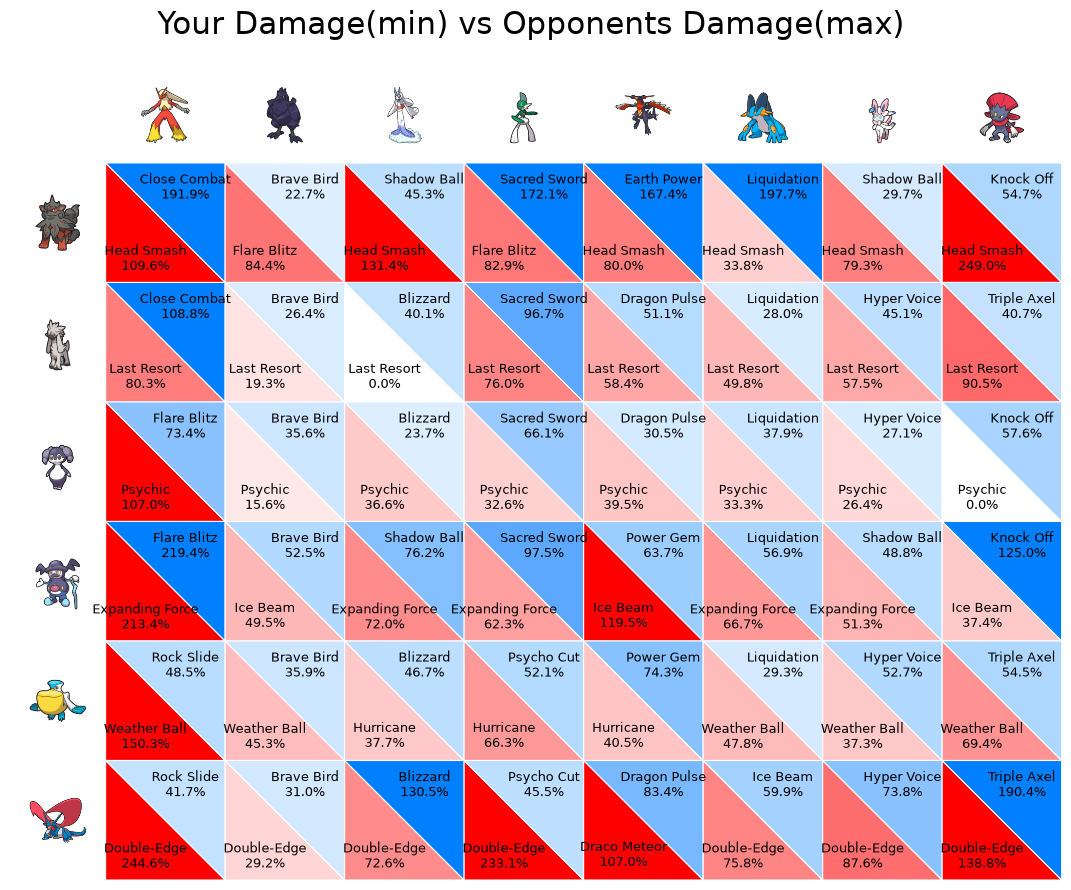

In [164]:
def sprite_path_for(name):
    slug = re.sub(r"[^a-z0-9]+", "-", name.casefold()).strip("-")
    candidates = [sprite_dir / f"{slug}.png"]
    if slug.endswith("-f"):
        candidates.append(sprite_dir / f"{slug[:-2]}-female.png")
    for path in candidates:
        if path.is_file():
            return path
    searched = ", ".join(str(path) for path in candidates)
    raise FileNotFoundError(f"No sprite found for {name!r}; checked: {searched}")

def add_sprite(ax, name, x, y, zoom=0.35):
    image = plt.imread(sprite_path_for(name))
    icon = OffsetImage(image, zoom=zoom)
    box = AnnotationBbox(
        icon,
        (x, y),
        frameon=False,
        annotation_clip=False,
    )
    ax.add_artist(box)

outgoing_damage = forward_best_attacks_df.pivot(
    index="attacker", columns="defender", values="min_damage_percent"
)
outgoing_moves = forward_best_attacks_df.pivot(
    index="attacker", columns="defender", values="move"
)
incoming_damage = reverse_best_attacks_df.pivot(
    index="defender", columns="attacker", values="min_damage_percent"
)
incoming_moves = reverse_best_attacks_df.pivot(
    index="defender", columns="attacker", values="move"
)

your_names = outgoing_damage.index
opponent_names = outgoing_damage.columns
incoming_damage = incoming_damage.reindex(index=your_names, columns=opponent_names)
incoming_moves = incoming_moves.reindex(index=your_names, columns=opponent_names)

norm = Normalize(vmin=0, vmax=100)
fig, ax = plt.subplots(
    figsize=(max(10, 2.4 * len(opponent_names)), max(6, 1.5 * len(your_names)))
)
triangles = []
facecolors = []

for row, your_name in enumerate(your_names):
    for col, opponent_name in enumerate(opponent_names):
        outgoing = outgoing_damage.loc[your_name, opponent_name]
        incoming = incoming_damage.loc[your_name, opponent_name]

        if pd.notna(outgoing):
            triangles.append([(col, row + 1), (col + 1, row + 1), (col, row)])
            facecolors.append(cmap_red(norm(outgoing)))
            ax.text(
                col + 1 / 3,
                row + 2 / 3,
                f"{outgoing_moves.loc[your_name, opponent_name]}\n{outgoing:.1f}%",
                ha="center",
                va="top",
                fontsize=9,
                #fontweight="bold",
            )

        if pd.notna(incoming):
            triangles.append([(col + 1, row), (col + 1, row + 1), (col, row)])
            facecolors.append(cmap_blue(norm(incoming)))
            ax.text(
                col + 2 / 3,
                row + 1 / 3,
                f"{incoming_moves.loc[your_name, opponent_name]}\n{incoming:.1f}%",
                ha="center",
                va="bottom",
                fontsize=9,
                #fontweight="bold",
            )

ax.add_collection(
    PolyCollection(triangles, facecolors=facecolors, edgecolors="white", linewidths=0.8)
)
ax.set_xlim(0, len(opponent_names))
ax.set_ylim(len(your_names), 0)
ax.set_aspect("equal")

ax.set_xlim(-0.8, len(opponent_names))
ax.set_ylim(len(your_names), -0.8)

ax.set_xticks([i + 0.5 for i in range(len(opponent_names))], labels=[])
ax.set_yticks([i + 0.5 for i in range(len(your_names))], labels=[])
ax.tick_params(length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)

for col, name in enumerate(opponent_names):
    add_sprite(ax, name, col + 0.5, -0.4)

for row, name in enumerate(your_names):
    add_sprite(ax, name, -0.4, row + 0.5)

# ax.set_xticks([i + 0.5 for i in range(len(opponent_names))], labels=opponent_names)
# ax.set_yticks([i + 0.5 for i in range(len(your_names))], labels=your_names)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_title("Your Damage(min) vs Opponents Damage(max) ", pad=24, fontdict={"fontsize": 22})
# fig.colorbar(
#     ScalarMappable(norm=norm, cmap=cmap_red),
#     ax=ax,
#     fraction=0.025,
#     pad=0.04,
#     label="You -> Opponent damage (% of opponent HP)",
# )
# fig.colorbar(
#     ScalarMappable(norm=norm, cmap=cmap_blue),
#     ax=ax,
#     fraction=0.025,
#     pad=0.10,
#     label="Opponent -> You damage (% of your HP)",
# )
plt.tight_layout()
plt.show()

In [165]:
new_requests = []

super_bulk_flag = False

for i in range(0, 33):
    #edit matchup requests to make a new request with attack evs being 0-32
    for request in matchup_requests:
        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Adamant"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)
        
        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Modest"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)

        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Serious"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)

In [166]:
try:
    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": new_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

new_results = json.loads(result.stdout)

In [167]:
#remove new_results that deal 0 damage

for result, request in zip(new_results, new_requests):
    attacker = request["attacker"]
    result["attack_evs"] = attacker["evs"].get("atk", 0)
    result["special_attack_evs"] = attacker["evs"].get("spa", 0)
    result["nature"] = attacker.get("nature", "Serious")

new_results = [result for result in new_results if result["damage"] != 0]
new_results_df = pd.DataFrame(new_results)

attacker_stats = new_results_df["attackerStats"].apply(pd.Series)
attacker_stats = attacker_stats.add_prefix("attacker_")

defender_stats = new_results_df["defenderStats"].apply(pd.Series)
defender_stats = defender_stats.add_prefix("defender_")

new_results_df = pd.concat(
    [new_results_df.drop(columns="attackerStats"), attacker_stats],
    axis=1,
)

new_results_df = pd.concat(
    [new_results_df.drop(columns="defenderStats"), defender_stats],
    axis=1,
)

new_results_df['min_damage_percent'] = new_results_df['minDamage'] / new_results_df['defender_hp'] * 100
new_results_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attack_evs,special_attack_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
0,Salamence-Mega,Froslass-Mega,Double-Edge,Physical,"[109, 109, 111, 112, 114, 115, 117, 118, 118, ...",129,109,0+ Atk Aerilate Salamence-Mega Double-Edge vs....,0,0,...,126,130,140,175,90,90,173,120,179,62.285714
1,Salamence-Mega,Froslass-Mega,Double-Edge,Physical,"[90, 91, 91, 93, 94, 94, 96, 97, 99, 99, 100, ...",106,90,0- Atk Aerilate Salamence-Mega Double-Edge vs....,0,0,...,154,130,140,175,90,90,173,120,179,51.428571
2,Salamence-Mega,Froslass-Mega,Double-Edge,Physical,"[100, 100, 102, 103, 105, 106, 106, 108, 109, ...",118,100,0 Atk Aerilate Salamence-Mega Double-Edge vs. ...,0,0,...,140,130,140,175,90,90,173,120,179,57.142857
3,Salamence-Mega,Froslass-Mega,Draco Meteor,Special,"[78, 79, 79, 81, 82, 82, 84, 85, 85, 87, 87, 8...",93,78,0- SpA Salamence-Mega Draco Meteor vs. 30 HP /...,0,0,...,126,130,140,175,90,90,173,120,179,44.571429
4,Salamence-Mega,Froslass-Mega,Draco Meteor,Special,"[94, 96, 97, 99, 99, 100, 102, 103, 103, 105, ...",112,94,0+ SpA Salamence-Mega Draco Meteor vs. 30 HP /...,0,0,...,154,130,140,175,90,90,173,120,179,53.714286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8410,Arcanine-Hisui,Corviknight,Head Smash,Physical,"[84, 84, 85, 87, 87, 88, 90, 90, 91, 93, 93, 9...",99,84,32- Atk Arcanine-Hisui Head Smash vs. 19 HP / ...,32,32,...,161,100,142,192,117,154,65,124,87,43.750000
8411,Arcanine-Hisui,Corviknight,Head Smash,Physical,"[93, 93, 94, 96, 96, 97, 99, 100, 100, 102, 10...",109,93,32 Atk Arcanine-Hisui Head Smash vs. 19 HP / 2...,32,32,...,147,100,142,192,117,154,65,124,87,48.437500
8412,Arcanine-Hisui,Corviknight,Extreme Speed,Physical,"[18, 18, 18, 18, 19, 19, 19, 19, 19, 20, 20, 2...",21,18,32+ Atk Arcanine-Hisui Extreme Speed vs. 19 HP...,32,32,...,132,100,142,192,117,154,65,124,87,9.375000
8413,Arcanine-Hisui,Corviknight,Extreme Speed,Physical,"[15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 17, 1...",18,15,32- Atk Arcanine-Hisui Extreme Speed vs. 19 HP...,32,32,...,161,100,142,192,117,154,65,124,87,7.812500


In [168]:
#for each attack per pokemon per defender, find the move that deals the minimum damage percent that is closest to 100 without going under
def choose_best_index(group):
    at_least_100 = group[group["min_damage_percent"] >= 100]
    candidates = at_least_100 if not at_least_100.empty else group
    return (candidates["min_damage_percent"] - 100).abs().idxmin()

best_moves = new_results_df.loc[
    new_results_df.groupby(["attacker", "defender"], group_keys=False)
    .apply(choose_best_index)
]

In [169]:
best_moves

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attack_evs,special_attack_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
4539,Arcanine-Hisui,Blaziken,Head Smash,Physical,"[157, 159, 160, 163, 165, 166, 168, 171, 172, ...",186,157,17+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,17,17,...,118,100,142,157,189,90,117,90,132,100.000000
7896,Arcanine-Hisui,Corviknight,Flare Blitz,Physical,"[162, 164, 164, 168, 168, 170, 174, 174, 176, ...",192,162,30+ Atk Arcanine-Hisui Flare Blitz vs. 19 HP /...,30,30,...,130,100,142,192,117,154,65,124,87,84.375000
1466,Arcanine-Hisui,Froslass-Mega,Head Smash,Physical,"[176, 180, 180, 182, 186, 188, 188, 192, 194, ...",210,176,5 Atk Arcanine-Hisui Head Smash vs. 30 HP / 0 ...,5,5,...,120,100,142,175,90,90,173,120,179,100.571429
8133,Arcanine-Hisui,Gallade,Flare Blitz,Physical,"[145, 147, 150, 151, 153, 154, 156, 157, 159, ...",172,145,31+ Atk Arcanine-Hisui Flare Blitz vs. 32 HP /...,31,31,...,131,100,142,175,194,85,85,137,90,82.857143
8355,Arcanine-Hisui,Garchomp-Mega-Z,Head Smash,Physical,"[148, 150, 151, 153, 156, 157, 159, 160, 162, ...",175,148,32+ Atk Arcanine-Hisui Head Smash vs. 2 HP / 0...,32,32,...,132,100,142,185,135,105,212,105,203,80.000000
8118,Arcanine-Hisui,Swampert,Head Smash,Physical,"[70, 71, 72, 72, 73, 74, 75, 76, 77, 78, 78, 7...",83,70,31+ Atk Arcanine-Hisui Head Smash vs. 32 HP / ...,31,31,...,131,100,142,207,178,110,107,110,72,33.816425
8382,Arcanine-Hisui,Sylveon,Head Smash,Physical,"[153, 154, 156, 157, 159, 162, 163, 165, 166, ...",180,153,32+ Atk Arcanine-Hisui Head Smash vs. 23 HP / ...,32,32,...,132,100,142,193,76,102,165,150,86,79.274611
238,Arcanine-Hisui,Weavile,Flare Blitz,Physical,"[194, 198, 198, 200, 204, 206, 210, 210, 212, ...",230,194,0- Atk Arcanine-Hisui Flare Blitz vs. 2 HP / 0...,0,0,...,126,100,142,147,172,85,58,105,194,131.972789
8025,Furfrou,Blaziken,Last Resort,Physical,"[127, 129, 130, 132, 133, 135, 136, 138, 139, ...",150,127,31+ Atk Furfrou Last Resort vs. 2 HP / 0 Def B...,31,31,...,104,110,122,157,189,90,117,90,132,80.891720
8295,Furfrou,Corviknight,Last Resort,Physical,"[38, 38, 39, 39, 39, 40, 40, 41, 41, 42, 42, 4...",45,38,32+ Atk Furfrou Last Resort vs. 19 HP / 29 Def...,32,32,...,105,110,122,192,117,154,65,124,87,19.791667


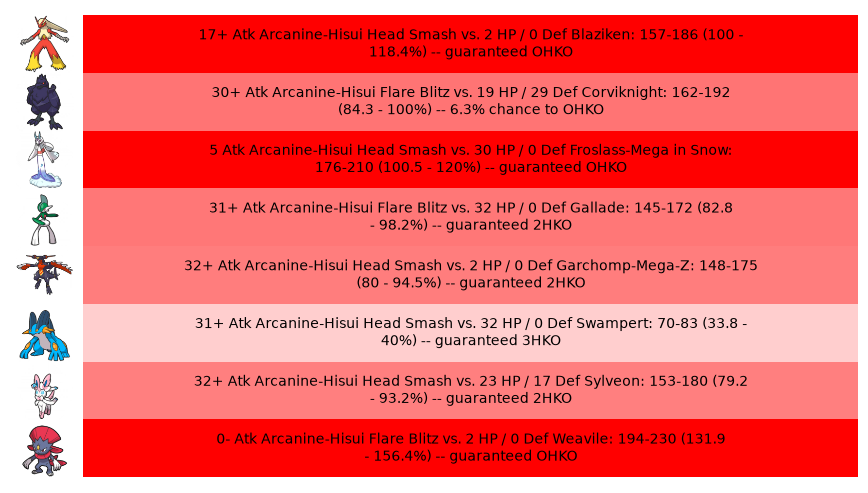

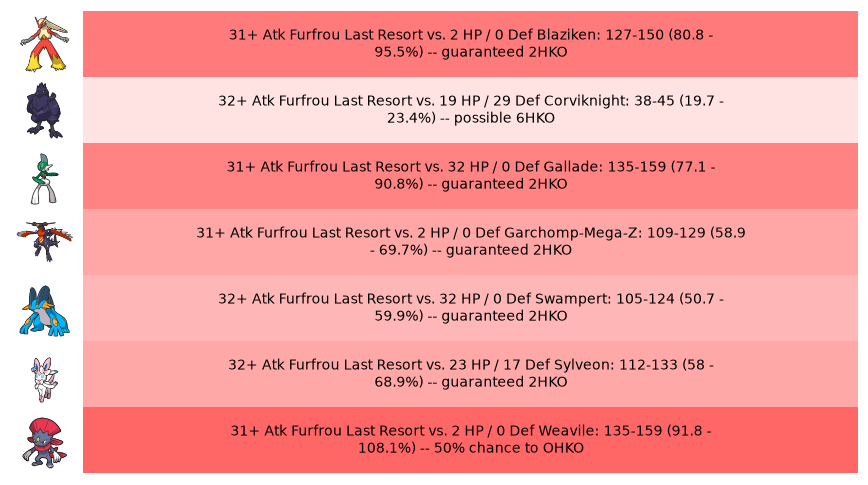

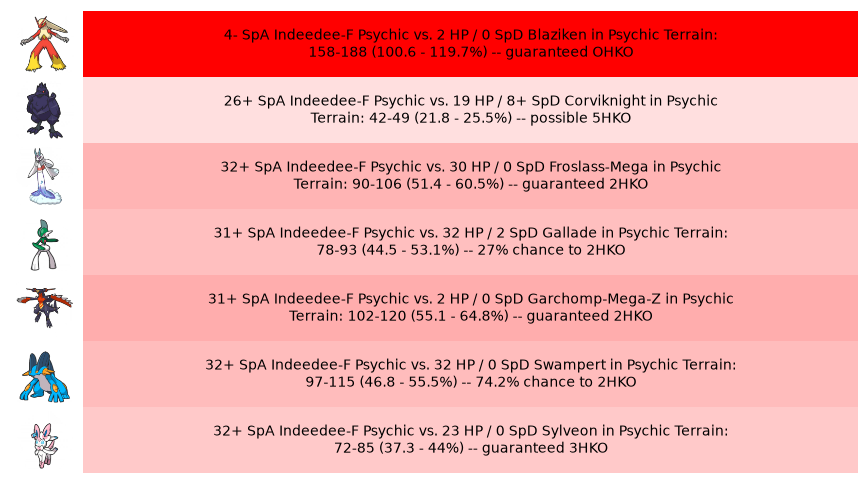

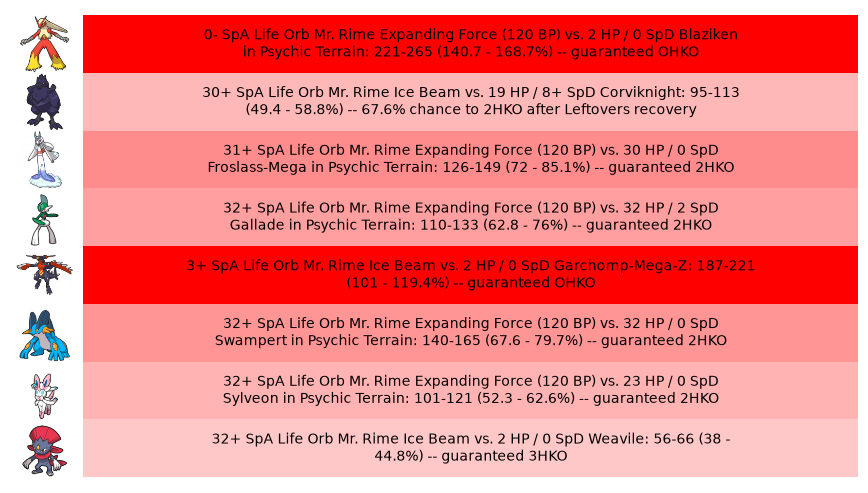

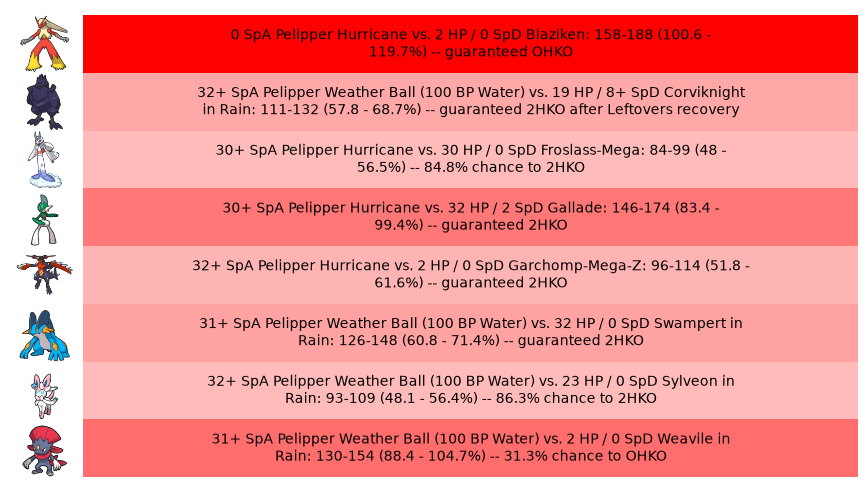

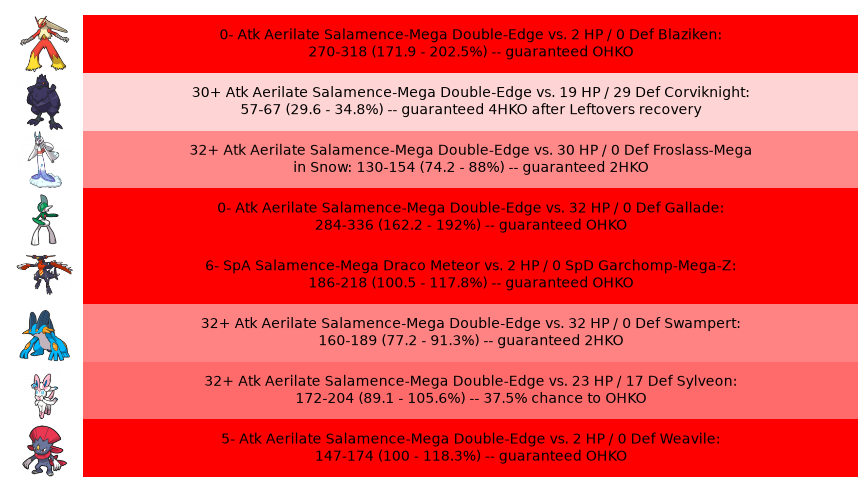

In [170]:
#for each attacker in best moves, create a simple table/heatmap showing the minimum damage percent against each defender

for attacker, group in best_moves.groupby("attacker"):
    group["wrapped_description"] = group["description"].apply(
        lambda text: textwrap.fill(str(text), width=75)
    )

    pivot_table = group.pivot(
        index="defender",
        columns="attacker",
        values="min_damage_percent"
    )
    description_table = group.pivot(
        index="defender",
        columns="attacker",
        values="wrapped_description",
    ).reindex(index=pivot_table.index, columns=pivot_table.columns)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(
        pivot_table,
        annot=description_table,
        fmt="",
        cmap=cmap_red,
        # cbar_kws={'label': 'Min Damage %'},
        vmin=0,
        vmax=100,
        annot_kws={"color": "black"},
        )

    #removing extra labels and colour bar
    ax.set_yticklabels([])
    ax.set_ylabel("")
    ax.tick_params(axis="y", length=0)
    ax.set_xticklabels([])
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=0)
    ax.collections[0].colorbar.remove()

     # Put each defender's sprite next to its heatmap row
    for row, defender in enumerate(pivot_table.index):
        filename = defender.lower().replace(" ", "-") + ".png"
        sprite_path = sprite_dir / filename

        if sprite_path.exists():
            image = mpimg.imread(sprite_path)
            sprite = OffsetImage(image, zoom=0.35)
            box = AnnotationBbox(
                sprite,
                (-0.05, row + 0.5),
                xycoords=ax.transData,
                frameon=False,
                box_alignment=(0.5, 0.5),
            )
            ax.add_artist(box)
    
    plt.show()